In [1]:
# 1. 데이터 준비: MNIST는 28×28 흑백 손글씨 이미지임
# 이 실습에서는 숫자 정답을 맞히지 않고 새로운 이미지를 생성
# 텐서 차원 (B,C,H,W)는 배치 크기, 채널 수, 높이, 너비임

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    # PIL 이미지를 (1,28,28) 실수 텐서로 변환하고 픽셀을 0~1 범위로 변환
    transforms.ToTensor(),     # (H, W, C) → (C, H, W), 값 범위 [0,1]
    # (픽셀-0.5)/0.5를 계산하여 -1~1로 바꿉니다. G의 Tanh 출력과 범위를 맞춤
    transforms.Normalize((0.5,), (0.5,))    # [0,1] → [-1,1]로 정규화
])

# 학습용 이미지 60,000장을 준비. 이미 다운로드한 파일은 재사용
dataset = datasets.MNIST(
    root='data',
    train=True,
    transform=transform,
    download=True
)

# 이미지를 최대 64장씩 배치 생성. 마지막 배치은 작을 수 있잇음
loader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=True
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 468kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.47MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 17.7MB/s]


In [2]:
# 2. 생성자 G: 무작위 잡음을 28×28 이미지로 변환
# ConvTranspose2d는 학습 가능한 필터로 공간 크기를 확장

import torch.nn as nn

class Generator(nn.Module):
    def __init__(self, latent_dim=64):
        # nn.Module 초기화로 하위 계층과 매개변수를 PyTorch가 관리하도록 설정
        super().__init__()
        # Sequential은 아래 계층을 위에서 아래 순서로 적용
        self.model = nn.Sequential(
            # 입력: (B, latent_dim, 1, 1)
            nn.ConvTranspose2d(latent_dim, 128, kernel_size=7, stride=1, padding=0),  # → (B,128,7,7)
            # 학습 시 채널별로 배치와 공간 축의 통계를 사용해 정규화
            nn.BatchNorm2d(128),
            # 음수는 0으로, 양수는 그대로 통과시켜 비선형성을 추가
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),          # → (B,64,14,14)
            # 학습 시 채널별로 배치와 공간 축의 통계를 사용해 정규화
            nn.BatchNorm2d(64),
            # 음수는 0으로, 양수는 그대로 통과시켜 비선형성을 추가
            nn.ReLU(),

            nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),            # → (B,1,28,28)
            # 최종 픽셀 값을 -1~1로 변환
            nn.Tanh()
        )

    # 모델(입력)을 호출하면 이 함수가 실행됨
    def forward(self, z):
        return self.model(z)

generator = Generator()

In [3]:
# 3. 판별자 D: 이미지마다 진짜라고 판단하는 값 하나를 출력
# 1에 가까우면 진짜, 0에 가까우면 가짜라는 판단
# Sigmoid와 BCE를 사용하는 DCGAN 예제이며 WGAN의 critic과는 다름

class Discriminator(nn.Module):
    def __init__(self):
        # nn.Module 초기화로 하위 계층과 매개변수를 PyTorch가 관리하도록 설정
        super().__init__()
        # Sequential은 아래 계층을 위에서 아래 순서로 적용
        self.model = nn.Sequential(
            # 입력: (B,1,28,28)
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1),     # → (B,64,14,14)
            # 음수 영역에도 기울기를 0.2만큼 남겨 학습 신호를 전달하도록 설정
            nn.LeakyReLU(0.2),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),   # → (B,128,7,7)
            # 학습 시 채널별로 배치와 공간 축의 통계를 사용해 정규화
            nn.BatchNorm2d(128),
            # 음수 영역에도 기울기를 0.2만큼 남겨 학습 신호를 전달하도록 설정
            nn.LeakyReLU(0.2),

            # 이미지별 특징 (128,7,7)을 길이 6272인 벡터로 펼침
            nn.Flatten(),                                             # → (B,128*7*7)
            # 6272개 특징을 이미지당 점수 하나로 합침. 출력은 (B,1)입니다.
            nn.Linear(128 * 7 * 7, 1),
            # 출력을 0~1로 바꿈. BCELoss가 받는 입력 범위임
            # 즉, 1에 가까우면 진짜, 0에 가까우면 가짜라는 판단 값
            nn.Sigmoid()
        )

    # 모델(입력)을 호출하면 이 함수가 실행됨
    def forward(self, x):
        return self.model(x)

discriminator = Discriminator()

In [4]:
# 4. 손실과 최적화: D와 G는 서로 다른 목표로 학습함
# D는 진짜에 1, 가짜에 0을 출력하도록 학습
# G는 자신이 만든 이미지에 D가 1을 출력하도록 학습


# 이진 교차 엔트로피: 예측이 목표 0 또는 1에서 벗어날수록 벌점을 줌
criterion = nn.BCELoss()

# G 전용 Adam 설정. generator.parameters()에 포함된 매개변수만 갱신
optimizer_G = torch.optim.Adam(
    generator.parameters(),
    # 학습률 설정
    lr=0.0002,
    # 기울기와 기울기 제곱의 이동평균 계수. DCGAN에서 자주 쓰는 설정임
    betas=(0.5, 0.999)
)

# D 전용 Adam 설정. G와 별도의 매개변수와 최적화(optimization) 상태를 관리
optimizer_D = torch.optim.Adam(
    discriminator.parameters(),
    # 학습률 설정
    lr=0.0002,
    # 기울기와 기울기 제곱의 이동평균 계수. DCGAN에서 자주 쓰는 설정임
    betas=(0.5, 0.999)
)

# 잠재 벡터의 길이(크기)
# Generator의 기본값 64와 일치해야 함
latent_dim = 64

Epoch 1/30 D=0.5767, G=2.2034
Epoch 2/30 D=0.5690, G=2.2379
Epoch 3/30 D=0.5731, G=2.2680
Epoch 4/30 D=0.5518, G=2.3172
Epoch 5/30 D=0.5379, G=2.3628
Epoch 6/30 D=0.5289, G=2.3980
Epoch 7/30 D=0.5294, G=2.4330
Epoch 8/30 D=0.5079, G=2.4848
Epoch 9/30 D=0.5066, G=2.4913
Epoch 10/30 D=0.4985, G=2.5390
Epoch 11/30 D=0.5162, G=2.5355
Epoch 12/30 D=0.4898, G=2.5794
Epoch 13/30 D=0.4885, G=2.5915
Epoch 14/30 D=0.4852, G=2.6268
Epoch 15/30 D=0.4847, G=2.6430
Epoch 16/30 D=0.4809, G=2.6675
Epoch 17/30 D=0.4843, G=2.6697
Epoch 18/30 D=0.4615, G=2.7234
Epoch 19/30 D=0.4632, G=2.7369
Epoch 20/30 D=0.4644, G=2.7534
Epoch 21/30 D=0.4596, G=2.7792
Epoch 22/30 D=0.4528, G=2.7790
Epoch 23/30 D=0.4761, G=2.7680
Epoch 24/30 D=0.4466, G=2.8261
Epoch 25/30 D=0.4497, G=2.8310
Epoch 26/30 D=0.4534, G=2.8625
Epoch 27/30 D=0.4444, G=2.8720
Epoch 28/30 D=0.4366, G=2.8822
Epoch 29/30 D=0.4491, G=2.8831
Epoch 30/30 D=0.4363, G=2.9124


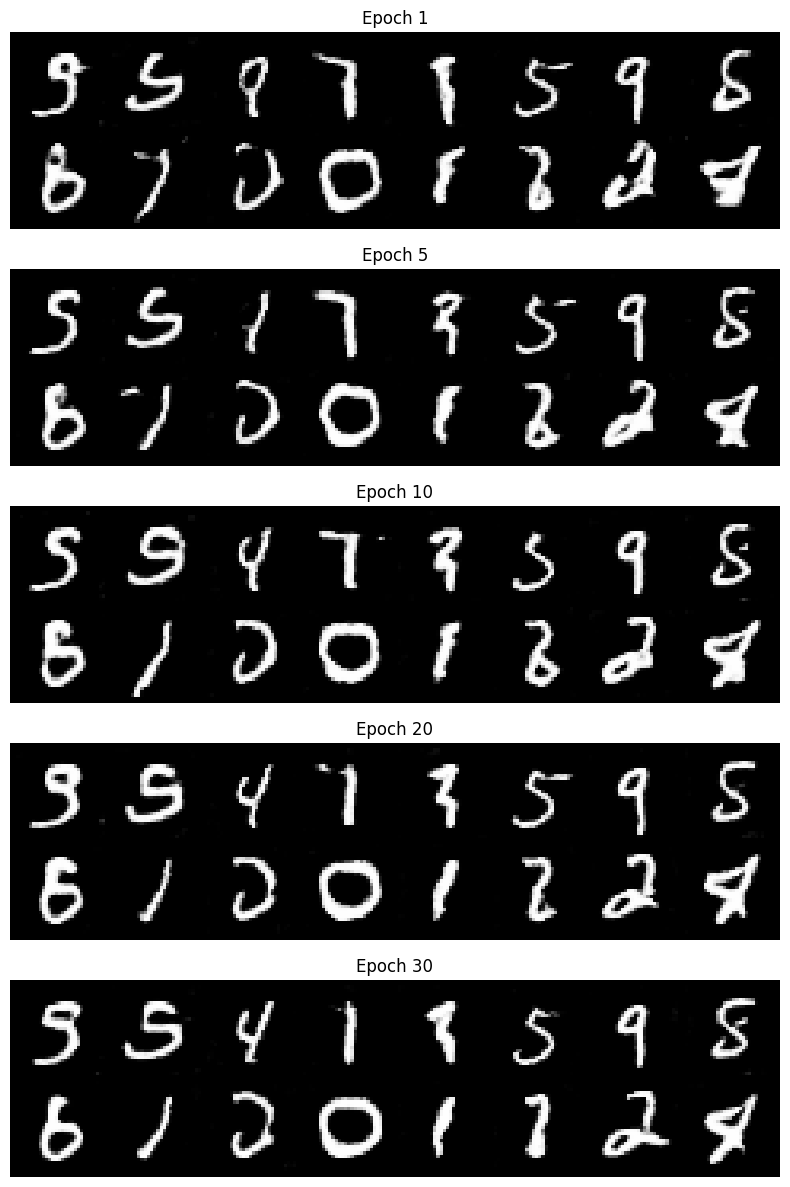

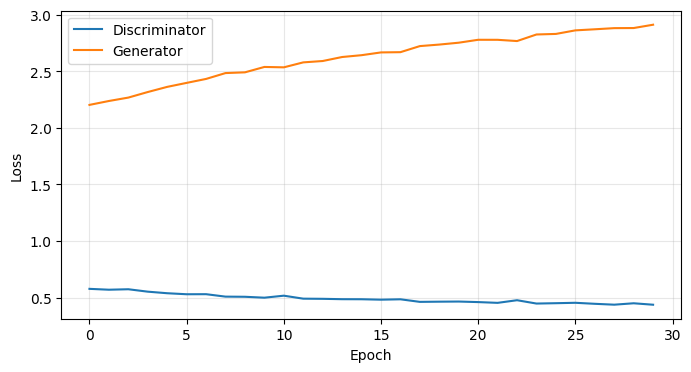

In [7]:

import torch
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

num_epochs = 30
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

generator.to(device)
discriminator.to(device)

# 학습 과정 비교용 고정 입력
torch.manual_seed(42)
fixed_noise = torch.randn(16, latent_dim, 1, 1, device=device)

g_losses = []
d_losses = []
snapshots = {}

for epoch in range(num_epochs):
    generator.train()
    discriminator.train()

    total_g = 0.0
    total_d = 0.0

    for real_imgs, _ in loader:
        real_imgs = real_imgs.to(device)
        batch_size = real_imgs.size(0)

        real_labels = torch.ones(batch_size, 1, device=device)
        fake_labels = torch.zeros(batch_size, 1, device=device)

        # 판별자 학습
        optimizer_D.zero_grad()

        z = torch.randn(batch_size, latent_dim, 1, 1, device=device)
        fake_imgs = generator(z)

        loss_real = criterion(discriminator(real_imgs), real_labels)
        loss_fake = criterion(discriminator(fake_imgs.detach()), fake_labels)

        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D.step()

        # 생성자 학습
        optimizer_G.zero_grad()

        loss_G = criterion(discriminator(fake_imgs), real_labels)
        loss_G.backward()
        optimizer_G.step()

        total_d += loss_D.item()
        total_g += loss_G.item()

    d_losses.append(total_d / len(loader))
    g_losses.append(total_g / len(loader))

    print(f"Epoch {epoch+1}/{num_epochs} "
          f"D={d_losses[-1]:.4f}, G={g_losses[-1]:.4f}")

    # 동일한 입력으로 생성 결과 저장
    if (epoch + 1) in [1, 5, 10, 20, 30]:
        generator.eval()
        with torch.no_grad():
            snapshots[epoch + 1] = generator(fixed_noise).cpu().clone()

# Epoch별 생성 이미지 비교
fig, axes = plt.subplots(len(snapshots), 1, figsize=(8, 12))

for ax, (epoch, images) in zip(axes, snapshots.items()):
    grid = make_grid((images + 1) / 2, nrow=8, padding=2)
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(f"Epoch {epoch}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# 손실 그래프
plt.figure(figsize=(8, 4))
plt.plot(d_losses, label="Discriminator")
plt.plot(g_losses, label="Generator")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


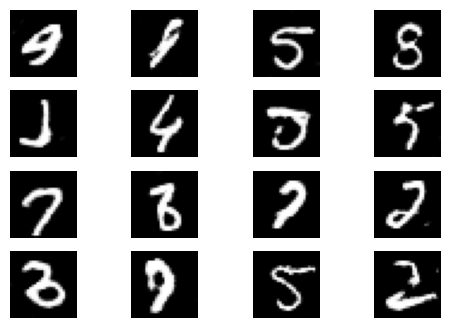

In [8]:
# 6. 새로운 잡음으로 이미지 16장을 생성해 확인
# 5 epoch만으로 선명한 숫자가 보장되지는 않음. 더 많은 epoch 학습 필요

import matplotlib.pyplot as plt

# 다시 학습할 때는 generator.train()을 호출해야 함
generator.eval()
with torch.no_grad():
    # 표준정규분포 N(0,1)에서 잠재벡터를 생성
    # 모양은 (B,latent_dim,1,1)임
    z = torch.randn(16, latent_dim, 1, 1).to(device)
    # Matplotlib에서 표시할 수 있도록 결과를 CPU로 옮김
    samples = generator(z).cpu()

plt.figure(figsize=(6, 4))
for i in range(16):
    # 4행 4열 중 i+1번째 칸임
    # 번호는 1부터 시작함
    plt.subplot(4, 4, i + 1)
    # squeeze로 채널 차원을 없애 (28,28)로 표시
    # 현재 명암은 이미지마다 자동 조정
    plt.imshow(samples[i].squeeze(), cmap='gray')
    plt.axis("off")
plt.show()
